In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow版本：", tf.__version__)

TensorFlow版本： 2.21.0


In [2]:
# 加载MNIST数据集
(x_train, y_train), (x_test, y_test) = \
    tf.keras.datasets.mnist.load_data()

print("训练图片：", x_train.shape)
print("训练标签：", y_train.shape)
print("测试图片：", x_test.shape)
print("测试标签：", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
训练图片： (60000, 28, 28)
训练标签： (60000,)
测试图片： (10000, 28, 28)
测试标签： (10000,)


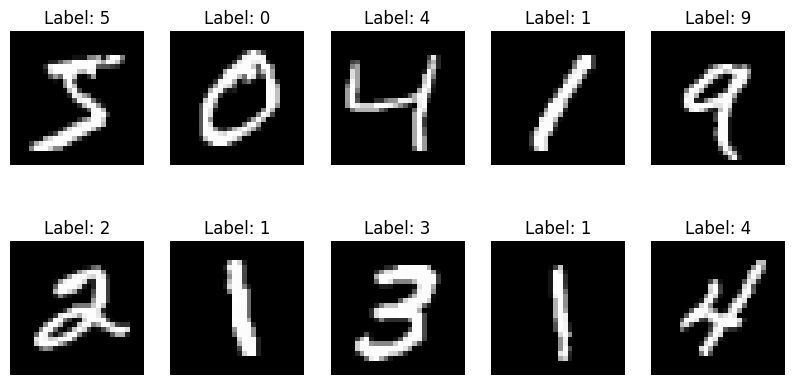

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Label: " + str(y_train[i]))
    plt.axis('off')

plt.show()

In [4]:
x_train = x_train / 255.0
x_test = x_test / 255.0

print("数据预处理完成！")

数据预处理完成！


In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),

    tf.keras.layers.Dense(
        128,
        activation='relu'
    ),

    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(
        10,
        activation='softmax'
    )
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("模型编译完成！")

模型编译完成！


In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9092 - loss: 0.3108 - val_accuracy: 0.9660 - val_loss: 0.1190
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9541 - loss: 0.1529 - val_accuracy: 0.9738 - val_loss: 0.0921
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9665 - loss: 0.1115 - val_accuracy: 0.9758 - val_loss: 0.0828
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9713 - loss: 0.0939 - val_accuracy: 0.9785 - val_loss: 0.0758
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9764 - loss: 0.0761 - val_accuracy: 0.9793 - val_loss: 0.0740


In [8]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test
)

print("测试损失：", test_loss)
print("测试准确率：", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9771 - loss: 0.0736
测试损失： 0.07355109602212906
测试准确率： 0.9771000146865845


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step
模型预测结果： 7
真实数字： 7


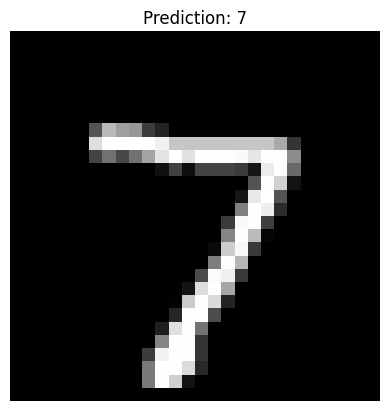

In [9]:
# 选择第一个测试图片
index = 0

image = x_test[index]

# 进行预测
prediction = model.predict(
    np.expand_dims(image, axis=0)
)

# 获取预测数字
predicted_label = np.argmax(prediction)

print("模型预测结果：", predicted_label)
print("真实数字：", y_test[index])

# 显示图片
plt.imshow(image, cmap='gray')
plt.title("Prediction: " + str(predicted_label))
plt.axis('off')
plt.show()

In [10]:
model.save("mnist_model.keras")

print("模型保存成功！")

模型保存成功！
